# ANN & Deep Learning
### CNN , ResNet-15 and U-Net

** Lab5 **

---

## Introduction

### What you will learn
In this lab you will look **inside** a CNN instead of treating it as a black box. You will:

* compute a convolution by hand and then in code,
* design simple filters and see what they detect,
* move to PyTorch layers (`Conv2d`, `ReLU`, `MaxPool2d`, ...),
* build, train and evaluate a small CNN on MNIST,
* calculate feature-map sizes and parameter counts,
* build a **ResNet-15** with residual (skip) connections,
* understand image segmentation and a **ResNet-15 + U-Net** architecture.





# PART 1 - Introduction to CNNs

### What is a CNN?
A **Convolutional Neural Network (CNN)** is a neural network designed for grid-like data such as images. Its main building block is the **convolution layer**, which slides small learnable filters over the image to detect patterns.

### Why is a fully connected network less suitable for images?
* A 28 x 28 image has 784 pixels. Flattening it destroys the 2D neighbourhood structure.
* A larger image (e.g. 224 x 224 x 3 = 150,528 values) would need millions of weights in the first layer alone.
* A fully connected layer learns a separate weight for every pixel position, so a digit shifted by a few pixels looks like a completely new input.

A CNN shares the same small filter across the whole image, so it needs far fewer parameters and can detect a pattern anywhere in the image.

### What does a CNN learn?
* **Early layers:** simple patterns such as edges and strokes.
* **Middle layers:** combinations of edges such as corners, curves and loops.
* **Deep layers:** larger shapes, such as a whole digit.

###


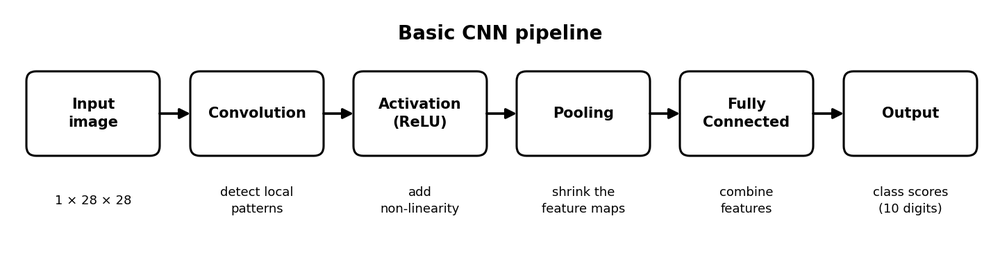



# PART 2 - MNIST Dataset and Image Representation

### What is MNIST?
MNIST contains **70,000 images of handwritten digits (0-9)**: 60,000 for training and 10,000 for testing.

* Image size: **28 x 28** pixels
* **Grayscale**, so there is **one channel**
* Raw pixel values are integers from **0 to 255** (0 = black, 255 = white)
* We **normalise** to **0-1** by dividing by 255. Small, consistent input values make training more stable.

### Tensor shape in PyTorch
PyTorch CNN layers expect input in the form:

**Batch × Channels × Height × Width**

For MNIST this is **Batch × 1 × 28 × 28**.

### Training, validation and test sets
We split the data into **three** parts, each with a different job:

| Set | Size here | Used for |
|---|---|---|
| **Training** | 55,000 | Updating the weights |
| **Validation** | 5,000 | Monitoring during training, choosing settings such as the number of epochs |
| **Test** | 10,000 | **One final** measurement of the finished model |

If we looked at the test set after every epoch and used it to make decisions, the test result would no longer be an honest estimate (this is a form of *data leakage*). So decisions are made on the **validation** set, and the **test** set is used only once at the end.

In [ ]:
# ---- Imports -------------------------------------------------------------
import torch                       # core tensor library
import torch.nn as nn              # layers (Conv2d, Linear, ...)
import torch.nn.functional as F    # stateless functions (relu, ...)
import torch.optim as optim        # optimisers (Adam, SGD, ...)

from torch.utils.data import DataLoader, Subset, TensorDataset, random_split
from torchvision import datasets, transforms   # MNIST and image transforms

import matplotlib.pyplot as plt    # plotting
import numpy as np                 # used for manual numerical operations

# ---- Reproducibility and device -----------------------------------------
# Fixed seeds make results repeatable, which helps when comparing experiments.
torch.manual_seed(42)
np.random.seed(42)

# Use a GPU if one is available (Colab: Runtime > Change runtime type > GPU),
# otherwise run on the CPU. The lab is small enough for a CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Running on:", device)

In [ ]:
# ---- Load MNIST ----------------------------------------------------------
# First load the RAW dataset (no transform) so we can see the original
# pixel range 0-255. The images are returned as PIL images.
raw_train = datasets.MNIST(root="./data", train=True, download=True)

# ToTensor() converts a PIL image to a float tensor of shape [1, 28, 28]
# AND divides all pixels by 255, so the values become 0-1.
transform = transforms.ToTensor()

# Training set (used to learn) and test set (used only to measure performance
# on data the model has never seen).
train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# DataLoaders serve the data in mini-batches. Training on batches is faster
# and more memory friendly than using all 60,000 images at once.
# shuffle=True for training so the model does not see the data in a fixed order.
# ---- Split the 60,000 training images into training (55,000) + validation (5,000) ----
# The validation images are NOT used to update the weights. They are used to check
# how well the model generalises while we are still training and tuning.
# A fixed generator seed makes the split identical every time the notebook runs.
train_subset, val_subset = random_split(train_dataset, [55000, 5000],
                                        generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_subset, batch_size=64,   shuffle=True)
val_loader   = DataLoader(val_subset,   batch_size=1000, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=1000, shuffle=False)   # used only ONCE at the end

print("Training images  :", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images      :", len(test_dataset))

# ---- Inspect the raw image (0-255) ---------------------------------------
raw_img, raw_label = raw_train[0]
raw_arr = np.array(raw_img)
print("\nRAW image  -> min:", raw_arr.min(), " max:", raw_arr.max(), " dtype:", raw_arr.dtype)

# ---- Inspect the normalised tensor (0-1) ---------------------------------
image, label = train_dataset[0]
print("TENSOR image -> shape:", tuple(image.shape),
      " min:", image.min().item(), " max:", image.max().item())
print("Label:", label)

# ---- Display --------------------------------------------------------------
# squeeze() removes the channel dimension [1,28,28] -> [28,28] for plotting.
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"MNIST training image | label = {label}")
plt.axis("off")
plt.show()

# ---- Batch shape ------------------------------------------------------------
# A DataLoader adds the batch dimension: [Batch, Channels, Height, Width].
images, labels = next(iter(train_loader))
print("One batch of images:", tuple(images.shape), "-> [Batch, Channels, Height, Width]")
print("One batch of labels:", tuple(labels.shape))

### TASK 2.1 - Explore another MNIST image

**What you need to do:** Change `student_index` to a different number (0 - 59999) and run the cell.

**What you should report:** the image, its label, its shape, its minimum value and its maximum value. Do the min and max change between different images? Why or why not?

In [ ]:
# ---- TASK 2.1: choose another image ------------------------------------
student_index = 5          # <-- CHANGE THIS NUMBER (0 to 59999)

img, lab = train_dataset[student_index]

# Print the requested information about the chosen image.
print("Label :", lab)
print("Shape :", tuple(img.shape))
print("Min   :", img.min().item())
print("Max   :", img.max().item())

plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"Index {student_index} | label = {lab}")
plt.axis("off")
plt.show()

# PART 3 - Manual Convolution



### Key terms
| Term | Meaning |
|---|---|
| **Convolution** | Sliding a small filter over an image and computing a weighted sum at each position |
| **Kernel / filter** | A small grid of numbers (e.g. 3 x 3) that detects a pattern |
| **Feature map** | The output image produced by applying one kernel |
| **Sliding window** | The image patch (same size as the kernel) currently under the kernel |
| **Element-wise multiplication** | Multiply each kernel value by the pixel below it |
| **Summation** | Add all those products to get **one** output number |
| **Stride** | How many pixels the kernel moves each step |
| **Padding** | Extra border of zeros added around the image |

> Note: deep-learning libraries actually compute *cross-correlation* (the kernel is not flipped). It is still called "convolution", and we follow that convention.

### Worked example: 5 x 5 image and 3 x 3 kernel

Image:

```text
1 2 0 1 3
0 1 3 1 2
2 1 0 2 1
1 0 2 3 0
3 1 1 0 2
```

Kernel (a vertical-edge detector, "Sobel"):

```text
 1  0 -1
 2  0 -2
 1  0 -1
```

**Step 1 - take the top-left 3 x 3 patch**

```text
1 2 0
0 1 3
2 1 0
```

**Step 2 - multiply element by element**

```text
1*1   2*0   0*(-1)        =  1   0   0
0*2   1*0   3*(-2)        =  0   0  -6
2*1   1*0   0*(-1)        =  2   0   0
```

**Step 3 - sum everything:** 1 + 0 + 0 + 0 + 0 - 6 + 2 + 0 + 0 = **-3**

This single number is the **top-left value of the feature map**. Then the kernel moves one step to the right (stride = 1) and we repeat.

### Output size formula

**Output size = floor( (Input + 2 x Padding - Kernel) / Stride ) + 1**

For our example: (5 + 0 - 3) / 1 + 1 = **3**, so the feature map is **3 x 3**.

* **Padding** adds zeros around the border so edges are processed properly and the output can keep the same size (for a 3 x 3 kernel, `padding=1` keeps the size).
* **Stride > 1** moves the kernel in bigger steps, which makes the output smaller.

In [ ]:
# ---- Manual convolution function -------------------------------------------
def manual_convolution(image, kernel, stride=1, padding=0):
    """Apply a 2D convolution WITHOUT nn.Conv2d or F.conv2d.

    image  : 2D array (H x W)
    kernel : 2D array (kH x kW)
    """
    # Work with float NumPy arrays so the arithmetic is precise and simple.
    image  = np.asarray(image,  dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)

    # 1) PADDING: add a border of zeros so the kernel can also be centred on
    #    edge pixels and the output does not shrink as much.
    if padding > 0:
        image = np.pad(image, pad_width=padding, mode="constant", constant_values=0)

    H, W   = image.shape
    kH, kW = kernel.shape

    # 2) Compute the output size with the formula from the Markdown above.
    out_h = (H - kH) // stride + 1
    out_w = (W - kW) // stride + 1

    # Empty feature map that we will fill in one value at a time.
    feature_map = np.zeros((out_h, out_w), dtype=np.float32)

    # 3) SLIDE the kernel over the image.
    for i in range(out_h):
        for j in range(out_w):
            top  = i * stride            # top row of the current window
            left = j * stride            # left column of the current window

            # The image patch currently under the kernel (the "sliding window").
            region = image[top:top + kH, left:left + kW]

            # 4) ELEMENT-WISE MULTIPLICATION and 5) SUM -> one output number.
            feature_map[i, j] = np.sum(region * kernel)

    return feature_map


# ---- Check with the hand-calculated example ---------------------------------
small_image = np.array([[1, 2, 0, 1, 3],
                        [0, 1, 3, 1, 2],
                        [2, 1, 0, 2, 1],
                        [1, 0, 2, 3, 0],
                        [3, 1, 1, 0, 2]])

sobel_x = np.array([[1, 0, -1],
                    [2, 0, -2],
                    [1, 0, -1]])

small_output = manual_convolution(small_image, sobel_x)
print("Feature map (3x3):\n", small_output)

# Testing against a value we calculated by hand proves the code is correct.
print("\nTop-left value:", small_output[0, 0])

### Apply manual convolution to an MNIST image
We now use the same function on a real digit and visualise the **image**, the **kernel** and the **feature map**.

In [ ]:
# Convert the tensor [1,28,28] into a plain 2D NumPy array [28,28].
mnist_img = train_dataset[0][0].squeeze().numpy()

# Same vertical-edge kernel as before. padding=1 keeps the output 28x28.
feature_map = manual_convolution(mnist_img, sobel_x, stride=1, padding=1)
print("Input shape      :", mnist_img.shape)
print("Feature map shape:", feature_map.shape)

# Show the three ingredients side by side.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(mnist_img, cmap="gray");  axes[0].set_title("Original image")
axes[1].imshow(sobel_x,  cmap="gray");   axes[1].set_title("Kernel (3x3)")
axes[2].imshow(feature_map, cmap="gray"); axes[2].set_title("Feature map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Interpretation:** the Sobel kernel responds strongly where pixel values change from left to right, i.e. at **vertical edges** of the digit. Flat areas (background or the inside of thick strokes) give values close to zero.

### TASK 3.1 - Change the kernel

**What you need to do:** Edit the `my_kernel` values (try the suggestions in the comments) and run the cell.

**What you should observe:** how the feature map changes. Which parts of the digit are highlighted or suppressed? What happens if all values are equal? What if the kernel is the transpose of the Sobel kernel?

In [ ]:
# ---- TASK 3.1: experiment with the kernel ---------------------------------
# Try these ideas one at a time:
#   1) A horizontal-edge kernel:  [[ 1, 2, 1], [ 0, 0, 0], [-1,-2,-1]]
#   2) All ones:                  [[ 1, 1, 1], [ 1, 1, 1], [ 1, 1, 1]]
#   3) Only the centre is 1:      [[ 0, 0, 0], [ 0, 1, 0], [ 0, 0, 0]]
my_kernel = np.array([[ 1,  2,  1],
                      [ 0,  0,  0],
                      [-1, -2, -1]])       # <-- CHANGE THESE VALUES

my_map = manual_convolution(mnist_img, my_kernel, stride=1, padding=1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(mnist_img, cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(my_kernel, cmap="gray"); axes[1].set_title("Your kernel")
axes[2].imshow(my_map,    cmap="gray"); axes[2].set_title("Your feature map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# PART 4 - Manual Filters / Kernels

A CNN **learns** its kernel values during training. Before that, it helps to see what **hand-designed** kernels do. Three classic examples:

| Filter | Idea | Effect |
|---|---|---|
| **Edge detection** | Positive and negative values around a zero centre | Highlights sudden intensity changes (outlines) |
| **Blur** | Average of the neighbourhood | Smooths the image and reduces noise |
| **Sharpen** | Strong centre, negative neighbours | Emphasises the centre pixel relative to its surroundings |

In [ ]:
# ---- Manually designed 3x3 kernels ------------------------------------------
# Edge: a Laplacian-type kernel. Values sum to 0, so flat regions -> 0 and
# only changes in intensity (edges) survive.
edge_kernel = np.array([[-1, -1, -1],
                        [-1,  8, -1],
                        [-1, -1, -1]])

# Blur: every neighbour contributes equally. Dividing by 9 keeps the overall
# brightness the same (the weights sum to 1).
blur_kernel = np.ones((3, 3)) / 9.0

# Sharpen: boosts the centre pixel and subtracts the neighbours,
# which makes strokes look crisper.
sharpen_kernel = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

# Apply each filter to the SAME image with our manual function.
# padding=1 keeps the output the same size as the input (28x28).
edge_out    = manual_convolution(mnist_img, edge_kernel,    padding=1)
blur_out    = manual_convolution(mnist_img, blur_kernel,    padding=1)
sharpen_out = manual_convolution(mnist_img, sharpen_kernel, padding=1)

# Visualise the results next to the original.
titles  = ["Original", "Edge filter", "Blur filter", "Sharpen filter"]
outputs = [mnist_img, edge_out, blur_out, sharpen_out]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, out, title in zip(axes, outputs, titles):
    ax.imshow(out, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Interpretation**

* **Edge filter:** only the outline of the digit remains bright; the flat interior is dark.
* **Blur filter:** the digit becomes softer and its edges spread out.
* **Sharpen filter:** the digit keeps its shape but the strokes look more contrasted.

A CNN does not use these fixed kernels. It *learns* many kernels automatically, choosing whatever patterns help the classification.

### TASK 4.1 - Create your own kernel

**What you need to do:** Create your own 3 x 3 kernel in `custom_kernel` and apply it.

**What you should observe:** which visual pattern (vertical lines, horizontal lines, diagonal strokes, edges, smooth areas) becomes **stronger** and which becomes **weaker**.

In [ ]:
# ---- TASK 4.1: design your own 3x3 kernel ---------------------------------
# Idea: a diagonal-edge detector. Change the numbers to experiment!
custom_kernel = np.array([[ 2,  1,  0],
                          [ 1,  0, -1],
                          [ 0, -1, -2]])      # <-- CHANGE THESE VALUES

custom_out = manual_convolution(mnist_img, custom_kernel, padding=1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(mnist_img,     cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(custom_kernel, cmap="gray"); axes[1].set_title("Custom kernel")
axes[2].imshow(custom_out,    cmap="gray"); axes[2].set_title("Custom output")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# PART 5 - PyTorch `Conv2d` Layer

### Manual vs PyTorch

| | Manual convolution | PyTorch `nn.Conv2d` |
|---|---|---|
| Kernel values | We **choose** them | **Learnable parameters**, updated during training |
| Speed | Slow Python loops | Fast optimised code (CPU / GPU) |
| Input | One 2D image | A batch of multi-channel images |

### `nn.Conv2d` arguments

| Argument | Meaning |
|---|---|
| `in_channels` | Number of channels of the input (1 for grayscale MNIST) |
| `out_channels` | Number of filters, i.e. number of feature maps produced |
| `kernel_size` | Size of each filter (3 means 3 x 3) |
| `stride` | Step size of the sliding window |
| `padding` | Zero border added to the input |

Each filter produces **one feature map**, so `out_channels=4` gives **4 feature maps**.

In [ ]:
# ---- Create a Conv2d layer ---------------------------------------------------
conv = nn.Conv2d(
    in_channels=1,    # MNIST is grayscale -> 1 input channel
    out_channels=4,   # 4 filters -> 4 feature maps
    kernel_size=3,    # every filter is 3x3
    stride=1,         # move one pixel at a time
    padding=1         # keep height/width unchanged (28 -> 28)
)

# PyTorch layers need a batch dimension, so [1,28,28] -> [1,1,28,28].
x = train_dataset[0][0].unsqueeze(0)

# torch.no_grad(): we only inspect the output, so we skip gradient tracking.
with torch.no_grad():
    out = conv(x)

print("Input shape          :", tuple(x.shape),   "-> [Batch, Channels, H, W]")
print("Output shape         :", tuple(out.shape), "-> 4 feature maps of 28x28")
print("Number of filters    :", conv.out_channels)
print("Kernel size          :", conv.kernel_size)
print("Weight tensor shape  :", tuple(conv.weight.shape), "-> [out_channels, in_channels, kH, kW]")
print("Bias shape           :", tuple(conv.bias.shape),   "-> one bias per filter")

### Verification: our manual function vs `nn.Conv2d`
If our manual implementation is correct, it must give the same result as PyTorch when both use the **same kernel**. We copy our Sobel kernel into a `Conv2d` layer and compare.

In [ ]:
# A Conv2d with one filter, and the same settings as our manual call.
check_conv = nn.Conv2d(1, 1, kernel_size=3, padding=1)

# Copy the Sobel kernel into the layer and set the bias to zero, so both
# methods use exactly the same numbers.
with torch.no_grad():
    check_conv.weight.copy_(torch.tensor(sobel_x, dtype=torch.float32).reshape(1, 1, 3, 3))
    check_conv.bias.zero_()
    torch_map = check_conv(x)[0, 0].numpy()

manual_map = manual_convolution(mnist_img, sobel_x, padding=1)

# allclose tolerates tiny floating-point differences.
print("Manual result equals PyTorch result:", np.allclose(manual_map, torch_map, atol=1e-5))

# PART 6 - Activation Functions

### Why do we need them?
Convolution is a **linear** operation (multiply and add). Stacking linear layers without anything in between is still just one linear operation. **Activation functions** add **non-linearity**, so the network can learn curved, complex decision rules.

| Function | Formula | Typical use |
|---|---|---|
| **ReLU** | `ReLU(x) = max(0, x)` | Hidden layers of CNNs (**our main choice**) |
| **Sigmoid** | `1 / (1 + e^-x)` | Squashes values into (0, 1); binary outputs |
| **Softmax** | `e^xi / sum(e^xj)` | Turns class scores into probabilities that sum to 1 |

ReLU keeps positive values and sets negative values to zero. It is cheap to compute and works well in deep networks.

In [ ]:
# ---- ReLU implemented by hand -----------------------------------------------
def manual_relu(x):
    # For every element take the larger of (x, 0): negatives become 0,
    # positives stay unchanged. This is exactly max(0, x).
    return torch.maximum(x, torch.tensor(0.0))

values = torch.linspace(-5, 5, 11)            # from -5 to 5
print("Input        :", values.tolist())
print("Manual ReLU  :", manual_relu(values).tolist())
print("F.relu       :", F.relu(values).tolist())

# Both give the same answer. F.relu is the optimised library version: it is
# faster, works on the GPU and supports automatic differentiation (needed
# for training). manual_relu shows the idea, F.relu is used in real models.
print("Same result  :", torch.equal(manual_relu(values), F.relu(values)))

# ---- Visualise ReLU, Sigmoid and Softmax ------------------------------------
xs = torch.linspace(-6, 6, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(xs, F.relu(xs));    axes[0].set_title("ReLU")
axes[1].plot(xs, torch.sigmoid(xs)); axes[1].set_title("Sigmoid")

# Softmax works on a vector of class scores (not element by element).
scores = torch.tensor([2.0, 1.0, 0.1])
axes[2].bar(["class 0", "class 1", "class 2"], F.softmax(scores, dim=0))
axes[2].set_title("Softmax of [2.0, 1.0, 0.1]")

for ax in axes[:2]:
    ax.grid(True); ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()
plt.show()

### TASK 6.1 - Try ReLU on your own values

**What you need to do:** Put your own numbers (positive, negative and zero) in `my_tensor`.

**What you should observe:** all negative numbers become 0 and all other numbers stay unchanged.

In [ ]:
# ---- TASK 6.1 ---------------------------------------------------------------
my_tensor = torch.tensor([-3.0, -0.5, 0.0, 1.5, 4.0])   # <-- CHANGE THESE VALUES

print("Input :", my_tensor.tolist())
print("ReLU  :", F.relu(my_tensor).tolist())

# PART 7 - Multiple Filters and Feature Maps

* **One filter → one feature map.**
* **Several filters → several feature maps** (one per filter), stacked as channels.
* Each filter has its own weights, so it can learn to detect a **different pattern** (vertical edge, horizontal edge, curve...).

Below, a `Conv2d` layer with 4 filters is applied to one digit. The filters here are **random (untrained)**, so the maps look different from each other but are not yet meaningful. After training, filters become specialised.

In [ ]:
# A conv layer with 4 filters; ReLU is applied afterwards, as in a real CNN.
conv4 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, padding=1)

with torch.no_grad():
    maps = F.relu(conv4(x))          # shape [1, 4, 28, 28]

print("Feature-map tensor shape:", tuple(maps.shape))

# Original image + the 4 feature maps.
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(mnist_img, cmap="gray"); axes[0].set_title("Original")
for k in range(4):
    axes[k + 1].imshow(maps[0, k], cmap="gray")
    axes[k + 1].set_title(f"Feature map {k + 1}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Interpretation:** each map highlights the digit in a different way because each filter has different weights. In a trained CNN these differences become useful, for example one map for vertical strokes and another for curves.

# PART 8 - Pooling Layers

### Why pooling?
* **Reduces the spatial size** (height and width), so later layers are cheaper.
* Makes the network slightly **tolerant to small shifts** of the pattern.
* Keeps the most important information.

| Type | Operation |
|---|---|
| **Max pooling** | Keeps the **largest** value in each window |
| **Average pooling** | Keeps the **mean** of each window |

### Small example (2 x 2 window, stride 2)

```text
Input 4x4                 Max pooling        Average pooling
 1  3 | 2  4                6   8              3.75  5.25
 5  6 | 7  8                3   4              2.00  2.00
-------+-------
 3  2 | 1  0
 1  2 | 3  4
```

For the top-left window `[[1,3],[5,6]]`: max = **6**, average = (1 + 3 + 5 + 6) / 4 = **3.75**. Each window is processed independently, and a 4 x 4 input becomes a 2 x 2 output.

The output size formula is the same as for convolution: **floor((Input - Kernel) / Stride) + 1**.

In [ ]:
# ---- Manual pooling functions ----------------------------------------------
def manual_max_pooling(feature_map, kernel_size=2, stride=2):
    """Max pooling on a 2D array without nn.MaxPool2d."""
    H, W  = feature_map.shape
    out_h = (H - kernel_size) // stride + 1    # same formula as convolution
    out_w = (W - kernel_size) // stride + 1
    out   = np.zeros((out_h, out_w), dtype=np.float32)

    for i in range(out_h):
        for j in range(out_w):
            window = feature_map[i * stride:i * stride + kernel_size,
                                 j * stride:j * stride + kernel_size]
            out[i, j] = window.max()           # keep only the strongest response
    return out


def manual_average_pooling(feature_map, kernel_size=2, stride=2):
    """Average pooling on a 2D array without nn.AvgPool2d."""
    H, W  = feature_map.shape
    out_h = (H - kernel_size) // stride + 1
    out_w = (W - kernel_size) // stride + 1
    out   = np.zeros((out_h, out_w), dtype=np.float32)

    for i in range(out_h):
        for j in range(out_w):
            window = feature_map[i * stride:i * stride + kernel_size,
                                 j * stride:j * stride + kernel_size]
            out[i, j] = window.mean()          # keep the average of the window
    return out


# ---- Small 4x4 example so we can check the numbers by eye -------------------
small_map = np.array([[ 1, 3, 2, 4],
                      [ 5, 6, 7, 8],
                      [ 3, 2, 1, 0],
                      [ 1, 2, 3, 4]], dtype=np.float32)

print("Input:\n", small_map)
print("\nMax pooling:\n", manual_max_pooling(small_map))
print("\nAverage pooling:\n", manual_average_pooling(small_map))

In [ ]:
# ---- Pool a real feature map (the edge-filter output from Part 4) -----------
max_pooled = manual_max_pooling(edge_out,     kernel_size=2, stride=2)
avg_pooled = manual_average_pooling(edge_out, kernel_size=2, stride=2)

print("Feature map :", edge_out.shape)
print("After pooling:", max_pooled.shape, "(height and width halved)")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(edge_out,   cmap="gray"); axes[0].set_title("Feature map 28x28")
axes[1].imshow(max_pooled, cmap="gray"); axes[1].set_title("Max pooling 14x14")
axes[2].imshow(avg_pooled, cmap="gray"); axes[2].set_title("Average pooling 14x14")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---- PyTorch pooling layers --------------------------------------------------
# The library versions work on [Batch, Channels, H, W] tensors.
fm_tensor = torch.tensor(edge_out).reshape(1, 1, 28, 28)

torch_max = nn.MaxPool2d(kernel_size=2, stride=2)(fm_tensor)
torch_avg = nn.AvgPool2d(kernel_size=2, stride=2)(fm_tensor)

print("\nPyTorch MaxPool2d output shape:", tuple(torch_max.shape))
print("PyTorch AvgPool2d output shape:", tuple(torch_avg.shape))

# Confirm that our manual versions match PyTorch.
print("Manual max == PyTorch max:", np.allclose(max_pooled, torch_max[0, 0].numpy(), atol=1e-5))
print("Manual avg == PyTorch avg:", np.allclose(avg_pooled, torch_avg[0, 0].numpy(), atol=1e-5))

**Interpretation:** the pooled maps are half the size but still show the digit shape. **Max pooling** keeps the sharpest responses, **average pooling** gives a smoother result. CNNs mostly use max pooling.

### TASK 8.1 - Change kernel size and stride

**What you need to do:** Change `k` and `s` and run the cell.

**What you should observe:** how the output height and width change. Verify the result with the formula `floor((28 - k) / s) + 1`.

In [ ]:
# ---- TASK 8.1 ---------------------------------------------------------------
k = 2      # <-- pooling window size (try 2, 3, 4)
s = 2      # <-- stride (try 1, 2, 3)

result = manual_max_pooling(edge_out, kernel_size=k, stride=s)
expected = (28 - k) // s + 1              # formula to compare with

print(f"kernel={k}, stride={s} -> output shape {result.shape}, formula predicts {expected} x {expected}")

# PART 9 - Building a Small CNN

Now we combine everything into one network:

**Input → Conv2d → ReLU → MaxPool → Conv2d → ReLU → MaxPool → Flatten → Linear → Output**

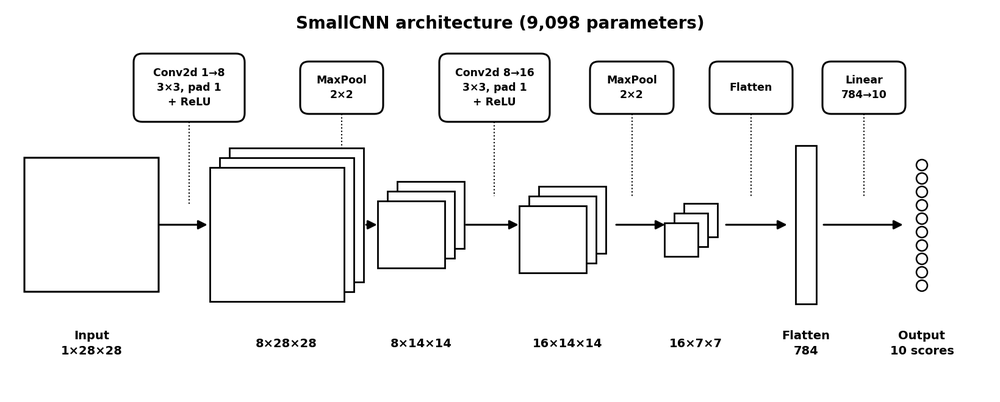

| Layer | Purpose |
|---|---|
| `Conv2d(1, 8, 3, padding=1)` | Learns 8 basic filters (edges, strokes) from the image |
| `ReLU` | Adds non-linearity |
| `MaxPool2d(2)` | Halves the size (28 → 14) |
| `Conv2d(8, 16, 3, padding=1)` | Learns 16 more complex patterns from the first maps |
| `ReLU` | Non-linearity again |
| `MaxPool2d(2)` | Halves the size again (14 → 7) |
| `Flatten` | Converts the 16 x 7 x 7 feature maps into a vector of 784 values |
| `Linear(784, 10)` | Converts features into 10 class scores (digits 0-9) |

The network outputs **raw scores (logits)**. We do not add Softmax, because `nn.CrossEntropyLoss` applies it internally.

In [ ]:
class SmallCNN(nn.Module):
    """A small CNN for 1x28x28 MNIST images.

    conv1_filters and conv2_filters are arguments so that we can easily
    change the network size later (Final Task 2).
    """
    def __init__(self, conv1_filters=8, conv2_filters=16, num_classes=10):
        super().__init__()

        # nn.Sequential runs the layers in the given order.
        self.net = nn.Sequential(
            # Block 1: look for basic patterns in the image.
            nn.Conv2d(1, conv1_filters, kernel_size=3, padding=1),  # 1x28x28 -> F1x28x28
            nn.ReLU(),                                              # non-linearity
            nn.MaxPool2d(2),                                        # -> F1x14x14

            # Block 2: combine basic patterns into more complex ones.
            nn.Conv2d(conv1_filters, conv2_filters, kernel_size=3, padding=1),  # -> F2x14x14
            nn.ReLU(),
            nn.MaxPool2d(2),                                        # -> F2x7x7

            # Classifier: turn feature maps into a vector, then into class scores.
            nn.Flatten(),                                           # -> F2*7*7
            nn.Linear(conv2_filters * 7 * 7, num_classes)           # -> 10 scores
        )

    def forward(self, x):
        # The forward pass simply sends the input through all layers.
        return self.net(x)


model = SmallCNN().to(device)
print(model)

# Quick sanity check: a batch of 4 images must give 4 x 10 scores.
dummy = torch.randn(4, 1, 28, 28).to(device)
print("\nInput :", tuple(dummy.shape))
print("Output:", tuple(model(dummy).shape), "-> [Batch, 10 class scores]")

**Interpretation:** printing the model lists the layers in order. The first half (Conv/ReLU/Pool) is the **feature extractor**, the last two layers (Flatten/Linear) are the **classifier**.

# PART 10 - CNN Training and Evaluation

### Key terms
| Term | Meaning |
|---|---|
| **Training set** | Data used to update the weights |
| **Validation set** | Held-out data used **during** training to monitor generalisation and to make decisions (e.g. how many epochs) |
| **Test set** | Data used **once, at the very end**, to report the final performance |
| **Epoch** | One full pass through the training set |
| **Batch size** | Number of images processed before each weight update (64 here) |
| **Loss** | A number that measures how wrong the predictions are (lower is better) |
| **Optimizer** | The algorithm that updates the weights to reduce the loss (Adam) |
| **Accuracy** | Percentage of correct predictions |

> **Why a validation set?** If you compare training loss with **validation loss**, you can see overfitting: training loss keeps falling while validation loss stops improving or rises. The test set is kept untouched so that the final number is fair.

We use `nn.CrossEntropyLoss()` (standard for multi-class classification) and `optim.Adam()` (a popular optimizer that adapts the learning rate automatically).

### The five steps of every training iteration
1. **Forward pass:** compute predictions.
2. **Loss calculation:** compare predictions with the true labels.
3. **`zero_grad()`:** clear old gradients (PyTorch accumulates them by default).
4. **Backpropagation** (`loss.backward()`): compute the gradient of the loss for every weight.
5. **`optimizer.step()`:** update the weights using the gradients.

In [18]:
# ---- Evaluation function ------------------------------------------------------
def evaluate(model, loader, criterion):
    """Return (average loss, accuracy %) on a data loader."""
    model.eval()                       # evaluation mode (matters for BatchNorm/Dropout)
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():              # no gradients needed -> faster, less memory
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            predictions = outputs.argmax(dim=1)          # class with the highest score
            correct += (predictions == labels).sum().item()
            total   += labels.size(0)

    return total_loss / total, 100.0 * correct / total


# ---- Training function --------------------------------------------------------
def train_model(model, train_loader, val_loader, epochs=3, lr=1e-3, use_scheduler=False):
    """Train a classification model and return the training/validation history.
    The test set is deliberately NOT used here."""
    criterion = nn.CrossEntropyLoss()                        # loss for 10-class problems
    optimizer = optim.Adam(model.parameters(), lr=lr)        # updates all learnable weights
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    # Optional learning-rate schedule: the learning rate decays smoothly to ~0 by the end
    # of training (cosine shape). Smaller final steps keep the weights stable, which also
    # lets BatchNorm's running statistics catch up (see Part 18).
    scheduler = None
    if use_scheduler:
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(train_loader))

    for epoch in range(epochs):
        model.train()                                        # training mode
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)                # 1) FORWARD PASS
            loss = criterion(outputs, labels)      # 2) LOSS CALCULATION
            optimizer.zero_grad()                  # 3) clear old gradients
            loss.backward()                        # 4) BACKPROPAGATION
            optimizer.step()                       # 5) UPDATE the weights
            if scheduler is not None:
                scheduler.step()                   # lower the learning rate a little

            # Track statistics for the plots below.
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total   += labels.size(0)

        train_loss, train_acc = running_loss / total, 100.0 * correct / total
        # Validation (NOT test): the model is evaluated on held-out data after each epoch.
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)
        print(f"Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} | train acc {train_acc:.2f}% "
              f"| val loss {val_loss:.4f} | val acc {val_acc:.2f}%")

    return history


def plot_history(history, title="Training history"):
    """Plot training vs validation loss and accuracy per epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
    axes[0].plot(epochs, history["val_loss"],   marker="s", label="Validation")
    axes[0].set_title("Loss")
    axes[1].plot(epochs, history["train_acc"],  marker="o", label="Training")
    axes[1].plot(epochs, history["val_acc"],    marker="s", label="Validation")
    axes[1].set_title("Accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.grid(True); ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
# ---- Train the SmallCNN  ------------------------
EPOCHS = 5           # <-- TASK 10.1: change this number
model = SmallCNN().to(device)
history = train_model(model, train_loader, val_loader, epochs=EPOCHS)

# ---- FINAL evaluation  ----
test_loss, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss())
print(f"\nFinal test loss    : {test_loss:.4f}")
print(f"Final test accuracy: {test_acc:.2f}%")

plot_history(history, "SmallCNN")

In [ ]:
# ----  what did the first layer learn? --------------------------------------
# After training, the 8 kernels of the first Conv2d are no longer random.
# Many of them look like edge or stroke detectors, similar to Part 4.
first_conv = model.net[0]
weights = first_conv.weight.detach().cpu()          # shape [8, 1, 3, 3]

fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for k, ax in enumerate(axes):
    ax.imshow(weights[k, 0], cmap="gray")
    ax.set_title(f"Filter {k + 1}", fontsize=9)
    ax.axis("off")
plt.suptitle("Learned 3x3 kernels of the first convolution layer")
plt.tight_layout()
plt.show()

**Interpretation**

* Training and validation loss should go **down** and accuracy **up**. A final test accuracy of about 97-99% after only a few epochs shows how effective even a tiny CNN is on MNIST.
* **Do not be surprised if the training loss is higher than the validation loss in the first epochs.** The training loss is an *average over the whole epoch* while the weights are still improving (and, later, Dropout/BatchNorm behave differently in training mode). The validation loss is measured *after* the epoch with the improved weights.
* If the training loss keeps decreasing but the validation loss starts to increase, the model is **overfitting**.
* The **test** loss and accuracy are computed only once, after training, so they are an honest estimate for new data.

### TASK 10.1 - Change the number of epochs

**What you need to do:** Go to the training cell, change `EPOCHS` (e.g. 1, 3, 6) and re-run it.

**What you should observe:** how training loss, validation loss and validation accuracy change. Base your decision on the **validation** curves, not on the test result. Does more training always help? When do the improvements become small?

# PART 11 - CNN Dimension and Parameter Calculation

### Dimension rules
* **Convolution:** `out = floor((in + 2 x padding - kernel) / stride) + 1`
* **Pooling:** `out = floor((in - kernel) / stride) + 1`
* Channels after a Conv layer = number of filters.

### Dimensions of our SmallCNN

| Stage | Output shape | Explanation |
|---|---|---|
| Input | 1 x 28 x 28 | grayscale MNIST |
| Conv2d(1→8, k=3, p=1) | 8 x 28 x 28 | (28 + 2 - 3)/1 + 1 = 28; 8 filters |
| MaxPool2d(2) | 8 x 14 x 14 | (28 - 2)/2 + 1 = 14 |
| Conv2d(8→16, k=3, p=1) | 16 x 14 x 14 | size preserved; 16 filters |
| MaxPool2d(2) | 16 x 7 x 7 | (14 - 2)/2 + 1 = 7 |
| Flatten | 784 | 16 x 7 x 7 = 784 |
| Linear(784→10) | 10 | one score per digit |

### Parameters of a convolution layer

**Parameters = (kernel height x kernel width x input channels + 1 bias) x number of filters**

Example, second conv layer (8 → 16, 3 x 3):

(3 x 3 x 8 + 1) x 16 = 73 x 16 = **1168**

Other layers:
* Conv1: (3 x 3 x 1 + 1) x 8 = **80**
* Linear: 784 x 10 weights + 10 biases = **7850**
* Pooling, ReLU and Flatten have **0 parameters**.
* **Total = 80 + 1168 + 7850 = 9098**

In [ ]:
# ---- Verify dimensions layer by layer -------------------------------------------
# We push one image through the network and print the shape after every layer.
model.eval()
t = torch.randn(1, 1, 28, 28).to(device)
print(f"{'Input':<12}{str(tuple(t.shape))}")

with torch.no_grad():
    for layer in model.net:
        t = layer(t)                                   # apply one layer at a time
        print(f"{layer.__class__.__name__:<12}{str(tuple(t.shape))}")

# ---- Parameters per layer --------------------------------------------------------
print("\nParameters per layer:")
for name, p in model.named_parameters():
    print(f"  {name:<12} shape {str(tuple(p.shape)):<16} -> {p.numel()} parameters")

# ---- Total number of learnable parameters ------------------------------------------
# numel() = number of elements in a tensor. Summing over all parameter tensors
# gives the total number of weights and biases the optimizer must learn.
total_params = sum(p.numel() for p in model.parameters())
print("\nTotal learnable parameters:", total_params, "(we calculated 9098 by hand)")

**Interpretation:** the total counts every weight and bias that is adjusted during training. Notice that the **Linear layer has most of the parameters** (7850 of 9098), although the convolution layers do most of the feature extraction. This is the benefit of weight sharing in convolution.

# PART 12 - Batch Normalization and Dropout

### Batch Normalization (`nn.BatchNorm2d`)
Normalises the activations of each channel (mean ≈ 0, variance ≈ 1) within a mini-batch. This usually makes training **more stable and faster**. It is placed after a convolution and before ReLU. It has learnable scale and shift parameters.

### Dropout (`nn.Dropout`)
During training, randomly sets a fraction `p` of activations to zero. The network cannot rely on a single neuron, which helps **reduce overfitting**. Dropout is automatically switched off in `model.eval()` mode.

In [ ]:
# ---- Dropout demo on a tiny tensor ---------------------------------------------------
drop = nn.Dropout(p=0.5)
ones = torch.ones(10)

drop.train()                                        # training mode: dropout is active
print("Train mode:", drop(ones).tolist(), " (survivors are scaled by 1/(1-p) = 2)")
drop.eval()                                         # eval mode: dropout does nothing
print("Eval mode :", drop(ones).tolist())

# ---- Adding BatchNorm and Dropout to our CNN -----------------------------------------
class SmallCNN_BN_Dropout(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.BatchNorm2d(8),        # normalise the 8 feature maps (needs #channels)
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.BatchNorm2d(16),       # normalise the 16 feature maps
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Dropout(p=0.25),       # randomly drop 25% of features before the classifier
            nn.Linear(16 * 7 * 7, num_classes)
        )

    def forward(self, x):
        return self.net(x)

bn_model = SmallCNN_BN_Dropout().to(device)
print("\n", bn_model)
print("Parameters:", sum(p.numel() for p in bn_model.parameters()),
      "(slightly more than before: BatchNorm adds a scale and shift per channel)")

# PART 13 - Data Augmentation

**Data augmentation** creates slightly modified versions of the training images on the fly. The model sees more variety and **generalises better** to new handwriting.

**Suitable transformations for digits:**
* small rotation (± 10-15°)
* small translation (shift by a few pixels)
* slight scaling (zoom in/out)

**Avoid:** horizontal or vertical flips and large rotations. A flipped **2** is no longer a 2, and a 180° rotated **6** looks like a **9**, which would create wrong training examples.

In [ ]:
# ---- Random affine transformation (rotation + shift + zoom) -----------------------
augment = transforms.RandomAffine(
    degrees=15,               # rotate randomly within ±15 degrees
    translate=(0.1, 0.1),     # shift up to 10% horizontally and vertically
    scale=(0.9, 1.1)          # zoom between 90% and 110%
)

# Augmentations work on the RAW PIL image, so we reuse raw_train from Part 2.
pil_img, pil_label = raw_train[0]

torch.manual_seed(0)          # fixed seed so the random examples are repeatable

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(pil_img, cmap="gray"); axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(augment(pil_img), cmap="gray")     # a new random variation each time
    axes[k].set_title(f"Augmented {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---- How augmentation is used in training ---------------------------------------------
# Augment only the TRAINING data. The test data must stay unchanged so that
# the test accuracy remains a fair measure.
train_transform_aug = transforms.Compose([
    augment,                       # random modification of the PIL image
    transforms.ToTensor()          # then convert to a tensor in the range 0-1
])
train_dataset_aug = datasets.MNIST(root="./data", train=True, download=True,
                                   transform=train_transform_aug)
print("Augmented training dataset created with", len(train_dataset_aug), "images")

### TASK 13.1 - Change one augmentation parameter

**What you need to do:** Change one value in `my_augment` (for example `degrees` to 45, or `translate` to 0.3) and run the cell.

**What you should observe:** how strongly the digit changes. At which value does the digit stop being clearly readable? What would this do to a model's training?

In [ ]:
# ---- TASK 13.1 ---------------------------------------------------------------------
my_augment = transforms.RandomAffine(
    degrees=45,               # <-- CHANGE (try 5, 15, 45, 90)
    translate=(0.1, 0.1),     # <-- CHANGE (try 0.0, 0.2, 0.3)
    scale=(0.9, 1.1)          # <-- CHANGE (try (0.5, 1.5))
)

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(pil_img, cmap="gray"); axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(my_augment(pil_img), cmap="gray")
    axes[k].set_title(f"Augmented {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# PART 14 - Transfer Learning

### What is transfer learning?
Training a large CNN from scratch needs a lot of data and computing time. In **transfer learning** we start from a **pretrained CNN** (already trained on a large dataset such as ImageNet with 1.2 million images) and re-use what it has learned.

### Pretrained CNN
A CNN whose weights were already learned on a large dataset. Its early layers detect general patterns (edges, textures) that are useful for almost any image task.

### Two common strategies
| Strategy | What happens | When to use |
|---|---|---|
| **Feature extraction** | Freeze the pretrained layers and train only a new classification layer | Small dataset, similar to the original data |
| **Fine-tuning** | Start from pretrained weights and continue training some or all layers with a small learning rate | More data, or data that differs somewhat |

### Well-known architectures
| Model | Main idea |
|---|---|
| **VGG** | Simple stack of 3 x 3 convolutions; deep but with many parameters |
| **ResNet** | Residual (skip) connections that make very deep networks trainable |
| **MobileNet** | Light-weight convolutions designed for phones and small devices |

We do **not** implement these here. The next parts study **ResNet** by building a small one manually.

# PART 15 - ResNet Introduction

### The problem: very deep CNNs are hard to train
Intuitively, a deeper network should be at least as good as a shallower one. In practice, after a certain depth the **training error gets worse** as layers are added. This is the **degradation problem**. (It is not simple overfitting, because even the *training* accuracy gets worse. Optimisation becomes harder because gradients must pass through many layers.)

### The idea: residual learning
Instead of forcing a group of layers to learn the full mapping `H(x)`, we let them learn the **residual** `F(x) = H(x) - x`, and add the input back:

**Output = F(x) + x**

If the best thing to do is "change nothing", the block only needs to learn `F(x) ≈ 0`, which is easy.

### Residual block and shortcut (skip) connection

```text
              ┌──────────── Shortcut ────────────┐
              │                                  │
Input ────────┴── Conv → ReLU → Conv ──→ Add ──→ ReLU
```


The **shortcut connection** lets the original input **bypass** the convolution layers and be **added** to their output. It also gives gradients a direct path backwards, which helps deep networks train.

> **Important:** in ResNet the shortcut uses **addition**, so both tensors must have the **same shape**. When the shape changes (more channels or smaller size), the shortcut uses a 1 x 1 convolution to match it ("projection shortcut").

# PART 16 -  ResNet-15 Architecture

We design a small ResNet for MNIST. The number **15** counts the **learnable weighted layers on the main path**: convolution layers and the final linear layer. (Batch normalisation, ReLU, pooling and the small 1 x 1 projection shortcuts are **not** counted, as in the ResNet-18/34 naming convention.)

### Layer count

| Component | Layers | Count |
|---|---|---|
| Stem | 2 x Conv 3x3 | **2** |
| Block 1 (stage 1) | 2 residual blocks x 2 conv | **4** |
| Block 2 (stage 2) | 2 residual blocks x 2 conv | **4** |
| Block 3 (stage 3) | 2 residual blocks x 2 conv | **4** |
| Head | Linear | **1** |
| **Total** | | **2 + 4 + 4 + 4 + 1 = 15** |

### Architecture

| Stage | Layer | Purpose | Output shape |
|---|---|---|---|
| Input | MNIST image | - | 1 x 28 x 28 |
| Stem | 2 x (Conv 3x3 + BN + ReLU), 8 filters | Initial feature extraction | 8 x 28 x 28 |
| Block 1 | 2 residual blocks, 8 channels | Feature learning | 8 x 28 x 28 |
| Block 2 | 2 residual blocks, 16 channels, **stride 2 in the first block** | Deeper features | 16 x 14 x 14 |
| Block 3 | 2 residual blocks, 32 channels, **stride 2 in the first block** | Higher-level features | 32 x 7 x 7 |
| Head | Global Average Pooling | Spatial reduction | 32 x 1 x 1 |
| Output | Linear (32 → 10) | 10 digit classes | 10 |

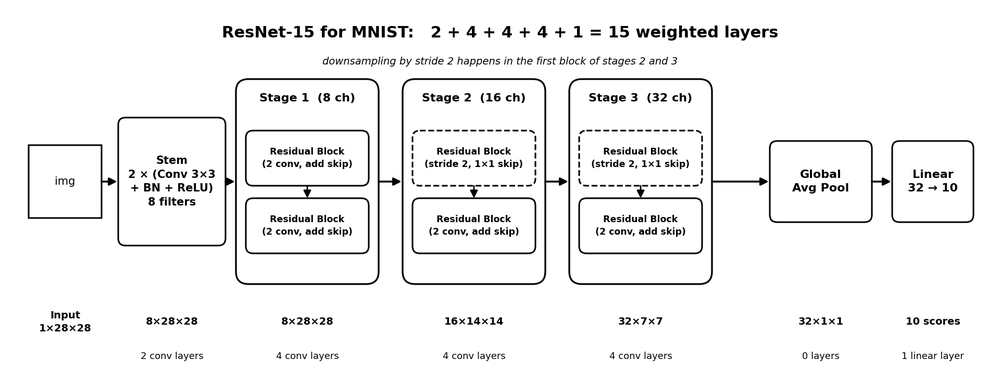

### Building blocks explained
* **Convolution block:** Conv2d → BatchNorm → ReLU.
* **Residual block:** Conv → BN → ReLU → Conv → BN, **add the shortcut**, then ReLU.
* **Shortcut connection:** identity (`x`) when the shape does not change; a **1 x 1 conv + BN** when it does.
* **Downsampling:** the first block of stages 2 and 3 uses `stride=2`, which halves height and width while the channels are doubled. This keeps the computation balanced.
* **Global Average Pooling:** averages each 7 x 7 map to a **single number**, giving one value per channel (32 values). It removes the need for a large Flatten + Linear layer.
* **Classification layer:** `Linear(32, 10)` gives one score per digit.

### Manual dimension calculation
* Stem: (28 + 2 - 3)/1 + 1 = 28 → **8 x 28 x 28**
* Block 1: stride 1, padding 1 → size unchanged → **8 x 28 x 28**
* Block 2: stride 2: (28 + 2 - 3)/2 + 1 = 14 (floor) → **16 x 14 x 14**
* Block 3: stride 2: (14 + 2 - 3)/2 + 1 = 7 (floor) → **32 x 7 x 7**
* Global average pooling → **32 x 1 x 1** → flatten → **32**
* Linear → **10**

### Parameters of one residual block (8 → 8 channels, identity)
We use `bias=False` in the convolutions because BatchNorm that follows already has its own shift term.

* Conv 1: 3 x 3 x 8 x 8 = **576**
* BatchNorm 1: 2 x 8 (scale + shift) = **16**
* Conv 2: 3 x 3 x 8 x 8 = **576**
* BatchNorm 2: 2 x 8 = **16**
* Identity shortcut: **0**
* **Total = 576 + 16 + 576 + 16 = 1184 parameters**



# PART 17 - Implement ResNet-15 in PyTorch

In [ ]:
class ResidualBlock(nn.Module):
    """Two 3x3 convolutions plus a shortcut connection.

        x ───────────────┐ (shortcut)
        └─ conv-bn-relu-conv-bn ─┴─ add ─ relu
    """
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # ---- Main path (the "residual" function F(x)) ----
        # bias=False: BatchNorm right after each conv has its own shift term.
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)

        # ---- Shortcut path ----
        # Addition needs both paths to have the SAME shape. If the block changes
        # the number of channels or the size, a 1x1 conv adapts the shortcut.
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()      # simply pass x through unchanged

    def forward(self, x):
        identity = self.shortcut(x)                 # 1) save the (adapted) input

        out = F.relu(self.bn1(self.conv1(x)))       # 2) first conv + BN + ReLU
        out = self.bn2(self.conv2(out))             # 3) second conv + BN (no ReLU yet)

        out = out + identity                        # 4) RESIDUAL CONNECTION: ADD the input back
        return F.relu(out)                          # 5) final ReLU


def make_stage(in_channels, out_channels, stride, num_blocks=2):
    """A stage = several residual blocks. Only the first one may downsample."""
    blocks = [ResidualBlock(in_channels, out_channels, stride)]
    for _ in range(num_blocks - 1):
        blocks.append(ResidualBlock(out_channels, out_channels, stride=1))
    return nn.Sequential(*blocks)


class ResNet15(nn.Module):
    """ResNet-15 for MNIST: 2 stem convs + 6 residual blocks (12 convs) + 1 linear = 15."""
    def __init__(self, num_classes=10, base=8):
        super().__init__()

        # Stem: 2 convolution layers (layers 1-2)
        self.stem = nn.Sequential(
            nn.Conv2d(1, base, 3, padding=1, bias=False), nn.BatchNorm2d(base), nn.ReLU(),
            nn.Conv2d(base, base, 3, padding=1, bias=False), nn.BatchNorm2d(base), nn.ReLU(),
        )
        # Three stages of 2 residual blocks each (layers 3-14)
        self.stage1 = make_stage(base,     base,     stride=1)   # 8  x 28 x 28
        self.stage2 = make_stage(base,     base * 2, stride=2)   # 16 x 14 x 14
        self.stage3 = make_stage(base * 2, base * 4, stride=2)   # 32 x 7  x 7

        # Head: global average pooling + linear classifier (layer 15)
        self.pool = nn.AdaptiveAvgPool2d(1)                      # any size -> 1x1
        self.fc   = nn.Linear(base * 4, num_classes)

    def forward(self, x):
        x = self.stem(x)               # basic feature extraction
        x = self.stage1(x)             # residual blocks, same resolution
        x = self.stage2(x)             # residual blocks, downsample to 14x14
        x = self.stage3(x)             # residual blocks, downsample to 7x7
        x = self.pool(x)               # [B, 32, 1, 1]
        x = torch.flatten(x, 1)        # [B, 32]
        return self.fc(x)              # [B, 10] class scores


resnet = ResNet15().to(device)
print(resnet)

In [ ]:
# ---- Verify the "15 layers"----------------------------------------
# Count the 3x3 convs (main path; the 1x1 projection shortcuts are not counted) + the Linear layer.
n_conv   = sum(1 for m in resnet.modules() if isinstance(m, nn.Conv2d) and m.kernel_size == (3, 3))
n_linear = sum(1 for m in resnet.modules() if isinstance(m, nn.Linear))
print(f"3x3 conv layers: {n_conv} | linear layers: {n_linear} | total weighted layers: {n_conv + n_linear}")
assert n_conv + n_linear == 15

# ---- Verify the manual parameter calculation of one block ------------------------------------
block = ResidualBlock(8, 8)
block_params = sum(p.numel() for p in block.parameters())
print("Parameters of one 8->8 residual block:", block_params, "(we calculated 1184 by hand)")

# ---- Feature-map dimensions after each stage ------------------------------------------------------
resnet.eval()
t = torch.randn(1, 1, 28, 28).to(device)
with torch.no_grad():
    print("\nInput  :", tuple(t.shape))
    for name, layer in [("stem", resnet.stem), ("stage1", resnet.stage1),
                        ("stage2", resnet.stage2), ("stage3", resnet.stage3),
                        ("avgpool", resnet.pool)]:
        t = layer(t)
        print(f"{name:<8}:", tuple(t.shape))
    t = resnet.fc(torch.flatten(t, 1))
    print("fc     :", tuple(t.shape))

# ---- Total number of parameters ---------------------------------------------------------------------
print("\nTotal ResNet-15 parameters:", sum(p.numel() for p in resnet.parameters()))

### TASK 17.1 -

**What you need to do:** Look at `ResidualBlock.forward` and find the line `out = out + identity`.

**What you should observe:** the input `x` never passes through `conv1` / `conv2` on the shortcut path: it reaches the addition unchanged (identity) or through only a 1 x 1 conv (when the shape changes). Which blocks in the printed ResNet-15 have a projection shortcut? (Hint: look for the `shortcut` with a `Conv2d` inside.)

# PART 18 - ResNet-15 MNIST Classification

We train the ResNet-15 with the **same training, validation and test procedure** as for the SmallCNN.

> **Note on BatchNorm (a real-world effect worth knowing):** ResNet-15 contains `BatchNorm2d` layers. In **training mode** they normalise with the statistics of the *current batch*; in **evaluation mode** they use *running averages* collected during training. When the weights are still changing quickly, these running averages lag behind, so the **validation accuracy can jump around or be lower than the training accuracy** in the first epochs, even though nothing is wrong with the code. Decaying the learning rate towards zero (cosine schedule, `use_scheduler=True`) makes the weights settle and gives stable validation results.

To keep the lab fast, we use a **subset of 20,000 training images** and only **3 epochs**. No hyperparameter tuning is performed. The goal is to see that ResNet works for classification.

In [ ]:
# ---- Use a 20,000 image subset of the training data to keep training fast --------------
subset = Subset(train_subset, range(20000))   # first 20,000 of the training split
subset_loader = DataLoader(subset, batch_size=64, shuffle=True)

resnet = ResNet15().to(device)                 # fresh (untrained) network
resnet_history = train_model(resnet, subset_loader, val_loader, epochs=3, lr=1e-3, use_scheduler=True)

# ---- FINAL evaluation on the test set (used once) ------------------------------------------
res_loss, res_acc = evaluate(resnet, test_loader, nn.CrossEntropyLoss())
print(f"\nResNet-15 final training loss  : {resnet_history['train_loss'][-1]:.4f}")
print(f"ResNet-15 final validation loss: {resnet_history['val_loss'][-1]:.4f}")
print(f"ResNet-15 test loss            : {res_loss:.4f}")
print(f"ResNet-15 test accuracy        : {res_acc:.2f}%")

# ---- Plot training and validation loss --------------------------------------------------------
ep = range(1, len(resnet_history["train_loss"]) + 1)
plt.plot(ep, resnet_history["train_loss"], marker="o", label="Training")
plt.plot(ep, resnet_history["val_loss"],   marker="s", label="Validation")
plt.legend()
plt.title("ResNet-15 training and validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True)
plt.show()

**Interpretation:** ResNet-15 reaches a high test accuracy after very few epochs. On a simple dataset such as MNIST a small CNN is already enough, so ResNet does not give a big advantage here. Its benefit appears on **harder datasets and much deeper networks**, where plain CNNs become difficult to train.

# PART 19 - Introduction to Image Segmentation

| Task | Output | Example |
|---|---|---|
| **Classification** | One class for the **whole image** | "This image contains the digit 7" |
| **Object detection** | **Bounding boxes** + class for each object | A box around every car in a street photo |
| **Semantic segmentation** | A class label for **every pixel** | Every pixel labelled as road, car, person, sky... |

Segmentation is used in medical imaging (tumour outlines), self-driving cars and satellite images.

> **Important:** MNIST is a **classification** dataset. It has only one label per image and **no pixel-level masks**, so it is **not suitable for a real U-Net training experiment**. Instead, we present the U-Net architecture conceptually and run a **small synthetic segmentation example** (images with random circles and squares plus their true masks) to show that the architecture works.

# PART 20 - U-Net Introduction

**U-Net** is a CNN designed for segmentation. It has a symmetric "U" shape:

**Encoder → Bottleneck → Decoder → Segmentation Mask**


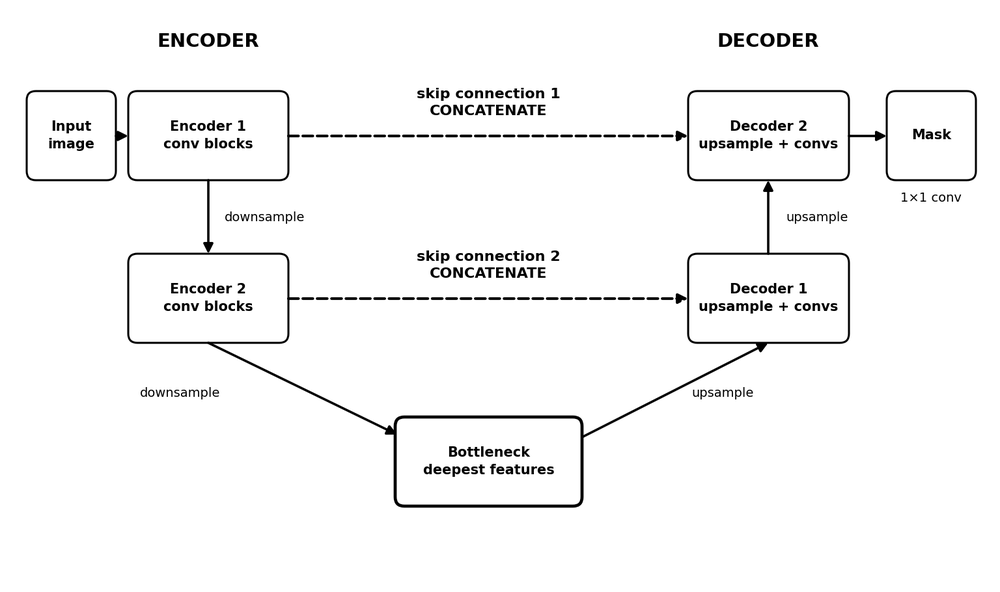

| Part | Job |
|---|---|
| **Encoder** | Repeated convolutions + downsampling. Extracts features, reduces resolution, increases channels |
| **Feature extraction** | The encoder learns *what* is in the image (shapes, objects) |
| **Bottleneck** | The smallest, deepest feature map: high-level meaning, very low resolution |
| **Decoder** | Restores the resolution step by step |
| **Upsampling** | Enlarges feature maps (e.g. `ConvTranspose2d` doubles height and width) |
| **Final segmentation layer** | A 1 x 1 convolution turns the last features into one score per class per pixel |




# PART 21 - Skip Connections in U-Net

### Why does U-Net need skip connections?
* The **encoder** extracts features but loses precise **spatial detail** as it downsamples.
* **Deep layers** know *what* is present (semantic information) but not exactly *where*.
* The **decoder** must produce a sharp, pixel-accurate mask, so it needs **spatial information**.
* **Skip connections** copy earlier (high-resolution) encoder feature maps to the decoder at the same resolution.

### ResNet skip vs U-Net skip: an important difference

| | ResNet skip connection | U-Net skip connection |
|---|---|---|
| Operation | **Addition** (`out + x`) | **Concatenation** (`torch.cat`) |
| Channels after combining | Unchanged | **Increase** (channels are added up) |
| Shapes required | Identical | Same height and width; channels may differ |
| Purpose | Make deep networks easier to train | Give the decoder fine spatial detail |
| Location | Inside one block | Between encoder and decoder |

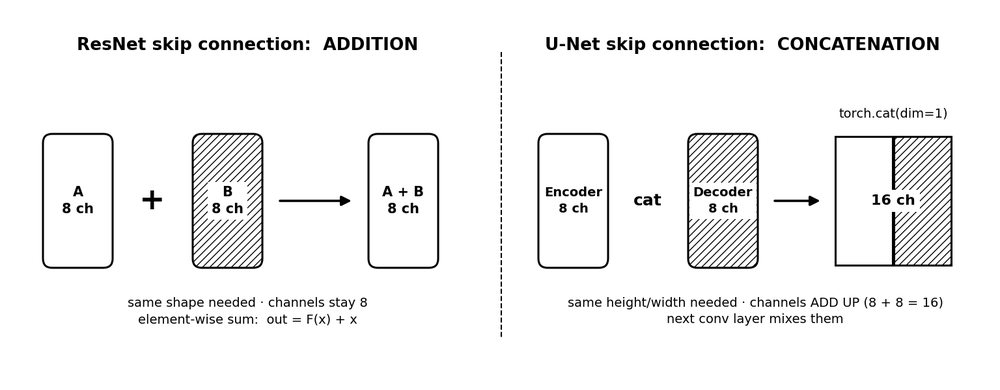

```text
Encoder Feature ───────────────┐
                               ↓
Decoder Feature → Concatenate → Convolution
```

Example: an encoder map with 8 channels + an upsampled decoder map with 8 channels → concatenation gives **16 channels**, and the next convolution mixes them.

In [ ]:
# ---- Addition vs concatenation on small tensors ---------------------------------------------
a = torch.ones(1, 8, 28, 28)               # e.g. an encoder feature map: 8 channels
b = torch.ones(1, 8, 28, 28) * 2           # e.g. an upsampled decoder feature map: 8 channels

added        = a + b                          # ResNet style: same shape as the inputs
concatenated = torch.cat([a, b], dim=1)       # U-Net style: dim=1 is the channel dimension

print("ResNet addition      :", tuple(added.shape),        "-> channels stay 8")
print("U-Net concatenation  :", tuple(concatenated.shape), "-> channels become 8 + 8 = 16")

# PART 21A - U-Net Basics:

Before the ResNet-15 + U-Net model,
### Where to read more

| Resource | Link | What to look at |
|---|---|---|
| **Original paper** | [Ronneberger, Fischer, Brox (2015), *U-Net: Convolutional Networks for Biomedical Image Segmentation*](https://arxiv.org/abs/1505.04597) | The "U" figure and the section on the architecture |
| **GitHub (PyTorch)** | **[github.com/milesial/Pytorch-UNet](https://github.com/milesial/Pytorch-UNet)** | `unet/unet_parts.py` (the building blocks) and `unet/unet_model.py` (the full network) |

> The GitHub repository is a widely used PyTorch U-Net, made for the Kaggle Carvana car-mask challenge. It is a good place to see the same ideas written as real project code. The code in this lab is our **own small version** in the same style, so the names are easy to compare.

### What is U-Net?
U-Net is a CNN for **image segmentation**: instead of one label per image, it predicts a label for **every pixel**. It was first designed for **biomedical images** (e.g. cell outlines), where only a few training images are available and the boundaries must be very precise. It is shaped like the letter **U**:

* the **left side (encoder)** goes *down*: the image gets smaller, the channels get more numerous, and the network learns **what** is in the image;
* the **bottom (bottleneck)** is the smallest, deepest part;
* the **right side (decoder)** goes *up*: the feature maps get larger again, and the network works out **where** things are;
* **skip connections** (the horizontal arrows) copy encoder feature maps straight across to the decoder at the same size.

### How it works, step by step

```text
Input image                                                   Segmentation mask
 1 x 28 x 28                                                     1 x 28 x 28
     |                                                                ^
 [DoubleConv] ---------- skip 1 (concatenate) ----------> [DoubleConv] + 1x1 conv
  8 x 28 x 28                                               8 x 28 x 28
     | MaxPool                                                  ^ Upsample (x2)
 [DoubleConv] ---------- skip 2 (concatenate) ----------> [DoubleConv]
 16 x 14 x 14                                              16 x 14 x 14
     | MaxPool                                                  ^ Upsample (x2)
              [   Bottleneck: DoubleConv   ]
                      32 x 7 x 7
```

1. **DoubleConv** is the basic block: `Conv 3x3 -> BatchNorm -> ReLU`, twice.
2. **Down (encoder):** `MaxPool2d(2)` halves height and width, then a DoubleConv doubles the number of channels.
3. **Bottleneck:** the smallest feature map (here 7 x 7). Each of its pixels "sees" a big part of the image.
4. **Up (decoder):** a transposed convolution (`ConvTranspose2d`, stride 2) **doubles** height and width again.
5. **Skip connection:** the matching encoder feature map is **concatenated** (`torch.cat`) with the upsampled one along the channel dimension. This brings back the fine detail lost by pooling. A DoubleConv then mixes both.
6. **Final 1 x 1 convolution:** turns the last feature map into one score per pixel for each class.

**Why it works:** the deep layers know *what* is there but have lost the exact position. The skip connections supply the *where*. Together they give sharp, pixel-accurate masks.



In [ ]:
# ---- A tiny U-Net (2 down steps) -------------
class DoubleConv(nn.Module):
    """(Conv 3x3 -> BatchNorm -> ReLU) x 2 : the basic U-Net building block."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class TinyUNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=1, base=8):
        super().__init__()
        self.pool  = nn.MaxPool2d(2)                                   # halves height and width
        # Encoder (left side of the U)
        self.enc1  = DoubleConv(in_ch,   base)                         # 28x28
        self.enc2  = DoubleConv(base,    base * 2)                     # 14x14
        # Bottleneck (bottom of the U)
        self.mid   = DoubleConv(base * 2, base * 4)                    # 7x7
        # Decoder (right side of the U): upsample, concatenate the skip, DoubleConv
        self.up2   = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2  = DoubleConv(base * 4, base * 2)                    # (skip 16 + up 16) -> 16
        self.up1   = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1  = DoubleConv(base * 2, base)                        # (skip 8 + up 8) -> 8
        # 1x1 conv: one score per class for every pixel
        self.out   = nn.Conv2d(base, n_classes, kernel_size=1)

    def forward(self, x, verbose=False):
        e1 = self.enc1(x)                              # skip 1
        e2 = self.enc2(self.pool(e1))                  # skip 2
        m  = self.mid(self.pool(e2))                   # bottleneck
        d2 = self.dec2(torch.cat([e2, self.up2(m)],  dim=1))   # CONCATENATE skip 2
        d1 = self.dec1(torch.cat([e1, self.up1(d2)], dim=1))   # CONCATENATE skip 1
        y  = self.out(d1)
        if verbose:
            for name, t in [("input", x), ("enc1 (skip 1)", e1), ("enc2 (skip 2)", e2),
                            ("bottleneck", m), ("dec2", d2), ("dec1", d1), ("output", y)]:
                print(f"{name:<15}{tuple(t.shape)}")
        return y


tiny = TinyUNet()
_ = tiny(torch.randn(1, 1, 28, 28), verbose=True)       # shape after every stage
print("\nTotal parameters:", sum(p.numel() for p in tiny.parameters()))

# ---- Optional: load the pretrained U-Net from the GitHub repo (needs internet; downloads a large model) ----
# big_unet = torch.hub.load('milesial/Pytorch-UNet', 'unet_carvana', pretrained=True, scale=0.5)

**Interpretation**

* The printed shapes follow the "U": the size goes **28 -> 14 -> 7** on the way down and **7 -> 14 -> 28** on the way up, while the channels go 8 -> 16 -> 32 and back to 8.
* The output has the **same height and width as the input** (28 x 28), with one channel: one score per pixel. After a sigmoid it becomes a foreground probability, which is exactly how the synthetic demo in PART 22 uses it.
* In `dec2` and `dec1` the DoubleConv takes **twice** as many input channels as it outputs, because the skip connection was concatenated (e.g. 16 skip + 16 upsampled = 32).

### TASK 21A.1 - Compare with the GitHub code

**What you need to do:** Open [`unet/unet_parts.py`](https://github.com/milesial/Pytorch-UNet) in the repository and find its `DoubleConv`, `Down`, `Up` and `OutConv` classes. Then (a) match each one to the corresponding part of `TinyUNet`, and (b) change `base=8` to `base=16` and re-run the cell.

**What you should observe:** which of our lines correspond to `Down` (`pool` + DoubleConv) and `Up` (`ConvTranspose2d` + `torch.cat` + DoubleConv), and how the number of parameters changes when the number of channels doubles.

# PART 22 - ResNet-15 Encoder + U-Net Decoder

Now we use the same U-Net idea, but the **encoder is replaced by our ResNet-15 backbone** (stem + residual stages from PART 17). The decoder and the **concatenation** skip connections are the same as in the tiny U-Net above. Note the two different kinds of skip connection in this model: **addition** inside every residual block (ResNet), and **concatenation** between encoder and decoder (U-Net).

In [ ]:
class DecoderBlock(nn.Module):
    """Upsample -> concatenate skip -> two convolutions."""
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        # UPSAMPLING: a transposed convolution with stride 2 doubles height and width.
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)

        # After concatenation we have (out_channels + skip_channels) channels.
        self.conv = nn.Sequential(
            nn.Conv2d(out_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
        )

    def forward(self, x, skip):
        x = self.up(x)                        # enlarge the decoder feature map
        x = torch.cat([skip, x], dim=1)       # SKIP CONNECTION: CONCATENATE along channels
        return self.conv(x)                   # let convolutions mix skip + decoder features


class ResNet15UNet(nn.Module):
    """Simplified educational ResNet-15 encoder + U-Net decoder."""
    def __init__(self, num_classes=1, base=8):
        super().__init__()

        # ---------------- ENCODER (ResNet-15 backbone, no classifier head) ----------------
        self.stem = nn.Sequential(
            nn.Conv2d(1, base, 3, padding=1, bias=False), nn.BatchNorm2d(base), nn.ReLU(),
            nn.Conv2d(base, base, 3, padding=1, bias=False), nn.BatchNorm2d(base), nn.ReLU(),
        )
        self.stage1 = make_stage(base,     base,     stride=1)   # 8  x 28 x 28  -> skip 1
        self.stage2 = make_stage(base,     base * 2, stride=2)   # 16 x 14 x 14  -> skip 2
        self.stage3 = make_stage(base * 2, base * 4, stride=2)   # 32 x 7  x 7   -> bottleneck

        # ---------------- DECODER ----------------
        self.dec1 = DecoderBlock(base * 4, base * 2, base * 2)   # 7x7  -> 14x14, uses skip 2
        self.dec2 = DecoderBlock(base * 2, base,     base)       # 14x14 -> 28x28, uses skip 1

        # ---------------- FINAL SEGMENTATION LAYER ----------------
        # 1x1 conv: for every pixel, combine the channels into 1 score
        # (foreground vs background). For more classes, raise num_classes.
        self.final = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder: extract features and keep the maps needed for the skips.
        x  = self.stem(x)
        s1 = self.stage1(x)         # high-resolution features (28x28) -> skip 1
        s2 = self.stage2(s1)        # medium-resolution features (14x14) -> skip 2
        bottleneck = self.stage3(s2)  # deepest, smallest features (7x7)

        # Decoder: upsample and concatenate the matching encoder features.
        d1 = self.dec1(bottleneck, s2)
        d2 = self.dec2(d1, s1)

        # Output: one raw score per pixel (a "logit" mask).
        return self.final(d2)


unet = ResNet15UNet().to(device)
dummy = torch.randn(2, 1, 28, 28).to(device)
print("Input shape :", tuple(dummy.shape))
print("Output shape:", tuple(unet(dummy).shape), "-> a 1-channel mask of the same 28x28 size")
print("Parameters  :", sum(p.numel() for p in unet.parameters()))

### Small synthetic segmentation demo
Because MNIST has no segmentation masks, we generate our own data: each image contains **one random circle or square** with noise, and the **mask** marks the shape pixels. We train briefly with `BCEWithLogitsLoss` (binary cross-entropy for a per-pixel yes/no decision).

In [ ]:
def make_synthetic_data(n, size=28, seed=0):
    """Create n noisy images with one circle or square each, plus their exact masks."""
    rng = np.random.default_rng(seed)
    images = np.zeros((n, 1, size, size), dtype=np.float32)
    masks  = np.zeros((n, 1, size, size), dtype=np.float32)
    yy, xx = np.mgrid[0:size, 0:size]                 # pixel coordinate grids

    for i in range(n):
        cx, cy = rng.integers(7, size - 7, 2)         # random centre
        r = rng.integers(3, 7)                        # random radius / half-size
        if rng.random() < 0.5:
            shape = (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2       # circle
        else:
            shape = (np.abs(xx - cx) <= r) & (np.abs(yy - cy) <= r)  # square
        masks[i, 0]  = shape
        images[i, 0] = 0.8 * shape + rng.normal(0, 0.15, (size, size))  # shape + noise
    return torch.tensor(np.clip(images, 0, 1)), torch.tensor(masks)

train_x, train_y = make_synthetic_data(800, seed=0)
val_x,   val_y   = make_synthetic_data(100, seed=1)      # validation: monitor training
test_x,  test_y  = make_synthetic_data(100, seed=2)      # test: used only once at the end (different seed = unseen data)
seg_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=32, shuffle=True)

# ---- Training loop (same 5 steps as before, but with a per-pixel loss) ----------------
unet = ResNet15UNet().to(device)
criterion = nn.BCEWithLogitsLoss()                      # per-pixel binary classification loss
optimizer = optim.Adam(unet.parameters(), lr=1e-3)

SEG_EPOCHS = 20
for epoch in range(SEG_EPOCHS):
    unet.train()
    total = 0.0
    for imgs, msks in seg_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        loss = criterion(unet(imgs), msks)              # forward + loss
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * imgs.size(0)

    # Validation loss after every epoch (no weight updates, eval mode).
    unet.eval()
    with torch.no_grad():
        val_loss = criterion(unet(val_x.to(device)), val_y.to(device)).item()
    print(f"Epoch {epoch + 1}/{SEG_EPOCHS} | train loss {total / len(train_x):.4f} | val loss {val_loss:.4f}")

# ---- FINAL evaluation on the unseen synthetic TEST images (used once) --------------------------
unet.eval()
with torch.no_grad():
    logits = unet(test_x.to(device)).cpu()
pred = (torch.sigmoid(logits) > 0.5).float()            # probability > 0.5 -> foreground

pixel_acc = (pred == test_y).float().mean().item() * 100
inter = (pred * test_y).sum().item()
union = ((pred + test_y) > 0).float().sum().item()
test_seg_loss = criterion(logits, test_y).item()
print(f"\nTest loss: {test_seg_loss:.4f}   |   Pixel accuracy: {pixel_acc:.2f}%   |   IoU: {inter / union:.3f}")

# ---- Visualise: image, true mask, predicted mask -------------------------------------------------
fig, axes = plt.subplots(3, 5, figsize=(11, 6.5))
for k in range(5):
    axes[0, k].imshow(test_x[k, 0],  cmap="gray"); axes[0, k].set_title("Input")
    axes[1, k].imshow(test_y[k, 0],  cmap="gray"); axes[1, k].set_title("True mask")
    axes[2, k].imshow(pred[k, 0],    cmap="gray"); axes[2, k].set_title("Predicted mask")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**Interpretation:** after only a few epochs the network finds the shapes in noisy images. Note that the loss can still be fairly high (e.g. around 0.2-0.3) while the pixel accuracy is already above 99%: the loss also measures how *confident* the predictions are, not only whether they are on the correct side of 0.5. More epochs would push the loss lower. The concatenated skip connections give the decoder the fine spatial detail it needs for sharp mask boundaries. (The exact metrics are only a demonstration on a very easy synthetic task.)




#  TASKS

Complete these five Task and write 2-3 sentences of observations for each.

### Task 1 - Manual Convolution
**What to do:** Change the manually created 3 x 3 kernel (Part 3, `my_kernel`).
**What to observe:** How different kernel values change the resulting feature map.

### Task 2 - Small CNN
**What to do:** Change the number of filters in the first `Conv2d` layer, e.g. `SmallCNN(conv1_filters=16)`.
**What to observe:** How the feature-map dimensions and the total number of parameters change. (Use the `named_parameters` cell of Part 11 to check.)

### Task 3 - Pooling
**What to do:** Change the pooling kernel size or stride (Part 8, `k` and `s`).
**What to observe:** How the spatial dimensions of the feature map change.

### Task 4 - ResNet
**What to do:** Inspect the `ResidualBlock` and identify where the shortcut connection is added.
**What to observe:** How the input bypasses the convolution layers.

### Task 5 - U-Net
**What to do:** Identify the encoder, bottleneck, decoder and skip connections in the ResNet-15 + U-Net architecture.
**What to observe:** How encoder features are transferred to the decoder.